# Simulación de un único rayo binario

Utilizaremos el fantoma del ejercicio anterior para simular una medición del modelo binario. Una dirección discreta está determinada por el par $(\alpha, \beta)$ y un desplazamiento entero $s$. El rayo correspondiente selecciona únicamente los píxeles cuyos centros satisfacen

$$\alpha i + \beta j = s$$


In [2]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

#### a) Implementar la función `mascara_rayo(n, direccion, s)`, que devuelva una matriz $M_r \in \{0, 1\}^{n \times n}$ con un 1 en los píxeles seleccionados por el rayo $r$ y un 0 en los restantes.

In [3]:
#n = filas/columnas de la matriz M
#direccion = (α, β)
#s satisface la ecuación αi + βj = s
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n)) #creamos la matriz de ceros
    i, j = np.ogrid[:n, :n] #indices de la matriz
    condicion=( i*direccion[0] + j*direccion[1] == s) #si  el pixel (i, j) es atravesado por el rayo r, lo marcamos con un 1
    M[condicion] = 1
    return M


mascara_rayo construye una matriz de ceros y unos que marca qué píxeles atraviesa un rayo, pone un 1 en los píxeles cuyo centro cumple $\alpha i + \beta j = s$ y un 0 en el resto. Es decir la **máscara** $M_r$ de un rayo

La ecuación $\alpha i + \beta j = s$ es la versión discreta de la recta $n_\theta^T p = s$ de la consigna. Dentro de la funcion, el par $(\alpha, \beta)$ fija la dirección de una familia de rayos paralelos y $s$ elige un rayo especifico de esa familia.

si se elije un $s$ que ningún píxel cumple , la función devuelve una matriz toda de ceros, que sería un rayo que no atraviesa la imagen.

#### b) Visualizar las máscaras para las direcciones (1, 0), (0, 1), (1, 1), (1, −1) y (2, 1), utilizando respectivamente los desplazamientos s = 3, 5, 7, 0, 8.

Para facilitar la comprensión y el análisis comparativo, se representaron gráficamente todos los desplazamientos posibles para cada dirección. Las combinaciones solicitadas específicamente en la consigna se destacaron en color verde

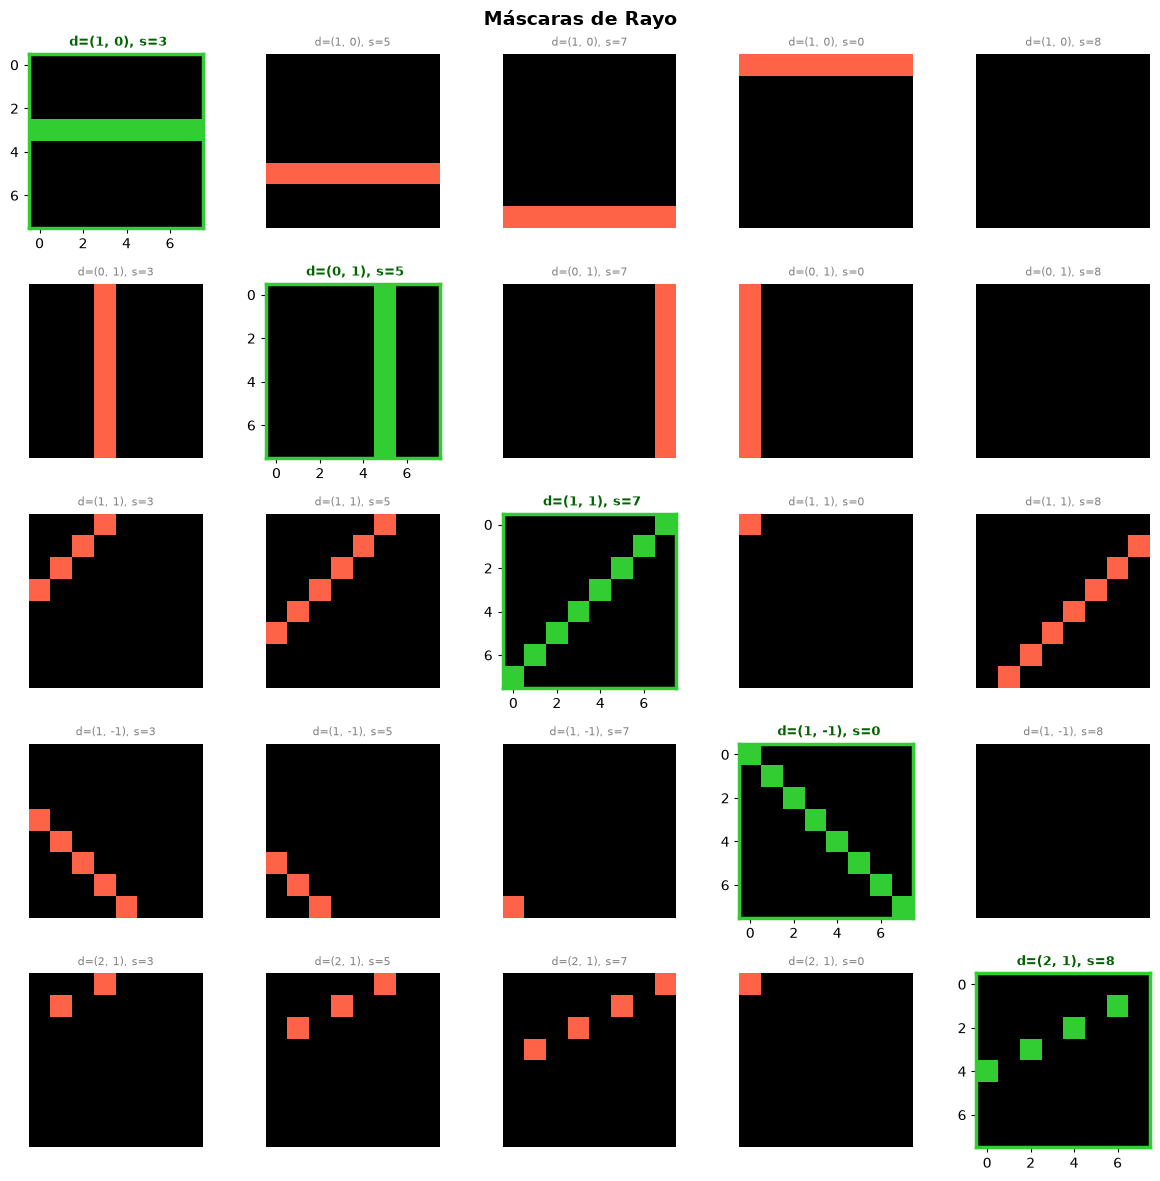

In [4]:
#Fantoma del ejercicio anterior
X_fantoma= np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

direcciones = [(1, 0), (0, 1), (1, 1), (1, -1), (2,1)]
desplazamientos = [3, 5, 7, 0, 8]
n = X_fantoma.shape[0] 

#Lista para guardar únicamente los resultados de las mediciones indicadas por la consigna
mediciones_consigna = []

#Diferenciar las máscaras de rayo que corresponden a la consigna (verde) de las que no (rojo)
cmap_consigna = ListedColormap(['black', 'limegreen'])
cmap_otros = ListedColormap(['black', 'tomato'])

#Creamos grilla de subplots para mostrar las máscaras de rayo
fig, axes = plt.subplots(len(direcciones), len(desplazamientos), figsize=(12, 12))

#Iteramos la funcion mascara_rayo sobre las direcciones y desplazamientos 
for row_idx, direccion in enumerate(direcciones):
    for col_idx, s in enumerate(desplazamientos):
        M = mascara_rayo(n, direccion, s)
        ax = axes[row_idx, col_idx]
        
        # Si la fila coincide con la columna, la pareja correspondo a la consigna
        es_de_consigna = (row_idx == col_idx)

        #Si es de consigna, usamos el cmap_consigna (verde), sino usamos cmap_otros (rojo)
        cmap_actual = cmap_consigna if es_de_consigna else cmap_otros
        #resaltamos los pixeles seleccionados por el rayo en la máscara M, usando el cmap_actual
        ax.imshow(M, cmap=cmap_actual, vmin=0, vmax=1)

        #formato del grafico: título, color de borde y grosor del borde
        if es_de_consigna:
            #guardamos las mediciones de la consigna en la lista mediciones_consigna, para utilizar en el siguiente ejercicio
            mediciones_consigna.append(M)
            ax.set_title(f' d={direccion}, s={s}', fontsize=9, fontweight='bold', color='darkgreen')
            for spine in ax.spines.values():
                spine.set_edgecolor('limegreen')
                spine.set_linewidth(2.5)
        else:
            ax.set_title(f'd={direccion}, s={s}', fontsize=8, color='gray')
            ax.axis('off')

plt.suptitle("Máscaras de Rayo", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('figuras/ejercicio_02b.png', dpi=150)
plt.show()


#### c) Para cada máscara, calcular la medición br = P i,j (Mr)ij (Xfantoma)ij mediante un producto componente a componente entre la máscara y el fantoma. (poner mejor la sumatioria )

In [5]:
# Medición de un rayo: producto componente a componente (*) entre la máscara y el fantoma,
# que deja solo los píxeles del rayo, y luego la suma de todos ellos
def medicion_br(M, X):
    return np.sum(M*X)

resultados_br = []
for M in mediciones_consigna:
    resultado = medicion_br(M, X_fantoma)
    resultados_br.append(resultado)

for direccion, s, resultado in zip(direcciones, desplazamientos, resultados_br):
    print(f"Dirección {direccion}, s = {s}: b_r = {resultado:.2f}")


Dirección (1, 0), s = 3: b_r = 2.30
Dirección (0, 1), s = 5: b_r = 2.40
Dirección (1, 1), s = 7: b_r = 1.20
Dirección (1, -1), s = 0: b_r = 1.90
Dirección (2, 1), s = 8: b_r = 1.10


#### d) Explicar por qué dos rayos con orientaciones diferentes pueden producir el mismo valor de medición aunque seleccionen distintos píxeles.

Como ejemplo, se comparan dos rayos del fantoma con orientaciones distintas: el horizontal $(1, 0)$ con $s = 6$ y el diagonal $(1, 1)$ con $s = 4$.

In [6]:
M_h = mascara_rayo(n, (1, 0), 6)   # fila 6 de la imagen
M_d = mascara_rayo(n, (1, 1), 4)   # antidiagonal i + j = 4

for nombre, M in [("horizontal (1,0), s=6", M_h), ("diagonal (1,1), s=4", M_d)]:
    pixeles = [(int(i), int(j)) for i, j in zip(*np.nonzero(M))]
    valores = X_fantoma[M == 1]
    print(f"Rayo {nombre}")
    print("  Píxeles con atenuación > 0:", [p for p, v in zip(pixeles, valores) if v > 0])
    print("  Valores:", valores[valores > 0])
    print(f"  b_r = {medicion_br(M, X_fantoma):.2f}\n")

Rayo horizontal (1,0), s=6
  Píxeles con atenuación > 0: [(6, 2), (6, 3), (6, 4), (6, 5)]
  Valores: [0.3 0.3 0.3 0.5]
  b_r = 1.40

Rayo diagonal (1,1), s=4
  Píxeles con atenuación > 0: [(1, 3), (2, 2), (3, 1)]
  Valores: [0.3 0.8 0.3]
  b_r = 1.40



La **máscara $M_r$.** Indica si el rayo pasó o no por cada píxel. Si la posición tiene un 1, el rayo "iluminó" ese píxel si tiene un 0, no lo hizo.

**Fantoma $X_{\text{fantoma}}$.** Es el objeto que analiza la tomografía y contiene el coeficiente de atenuación de cada píxel. Si es 0, el píxel no atenúa, es decir, deja pasar toda la intensidad del rayo. Cuanto mayor es el valor, más atenúa y menos intensidad deja pasar.

**Medición $b_r$.** Es la suma de los coeficientes de atenuación de los píxeles por los que pasó el rayo, es decir, la atenuación acumulada a lo largo del rayo

$$b_r = \sum_{i,j} (M_r)_{ij}\,(X_{\text{fantoma}})_{ij}$$

Dos rayos con distinta orientación pueden obtener la misma medición aunque atraviesen píxeles distintos, porque $b_r$ es un único número que resulta de una suma, y muchas combinaciones distintas de valores pueden dar la misma suma. En otras palabras, la medición solo informa el total, al sumar se pierde la información de cuánto atenúa cada píxel por separado y de dónde resulta la atenuación a lo largo del rayo.

En el ejemplo, los dos rayos atraviesan píxeles distintos, con valores distintos, y aun así miden exactamente lo mismo

$$0.3 + 0.3 + 0.3 + 0.5 = 1.40 \qquad\qquad 0.3 + 0.3 + 0.8 = 1.40$$